# Challenge — Red neuronal con Keras 3
### Universidad EAFIT | SI3003 — Introducción a la Inteligencia Artificial

---

## Objetivo

En clase construimos una red neuronal de clasificación con **Keras 3**.

En este ejercicio vas a aplicar la misma receta sobre un dataset diferente:

> **Olivetti Faces**

El dataset contiene imágenes de rostros en escala de grises. El objetivo será identificar a cuál persona pertenece cada imagen.

No necesitas diseñar un pipeline de datos nuevo. La carga, división y visualización están resueltas.

Tu trabajo se concentra en completar las etapas principales de Keras:

```text
Datos
  ↓
Modelo
  ↓
Loss + Optimizer
  ↓
Entrenamiento
  ↓
Evaluación
  ↓
Predicción
```

---

## ¿Qué debes completar?

Las celdas marcadas con `# TODO` contienen espacios que debes completar.

El resto del código está preparado para que puedas concentrarte en los conceptos vistos en clase.


---
## 0. Importar librerías

Usaremos:

- **Keras 3** para construir y entrenar la red.
- **scikit-learn** para cargar Olivetti Faces y dividir los datos.
- **NumPy** para manipular arrays.
- **Matplotlib** para visualizar imágenes.


In [26]:
import keras
from keras import layers

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.model_selection import train_test_split

SEED = 42
keras.utils.set_random_seed(SEED)

print(f"Keras version : {keras.__version__}")
print(f"Backend       : {keras.backend.backend()}")


Keras version : 3.13.2
Backend       : tensorflow


---
# 1. Dataset: Olivetti Faces

Olivetti Faces contiene:

- **400 imágenes**
- imágenes de **64 × 64 píxeles**
- escala de grises
- **40 personas**
- **10 imágenes por persona**

La etiqueta indica la identidad de la persona:

```text
0, 1, 2, ..., 39
```

Cada imagen ya viene representada con valores flotantes aproximadamente en el rango:

$$
[0,1]
$$

Por eso, en este ejercicio **no necesitamos normalizar dividiendo por 255**.


In [27]:
# Esta parte está resuelta.

faces = fetch_olivetti_faces(
    shuffle=True,
    random_state=SEED
)

X = faces.images
y = faces.target

print("X:", X.shape)
print("y:", y.shape)
print("Valor mínimo:", X.min())
print("Valor máximo:", X.max())
print("Número de clases:", len(np.unique(y)))


X: (400, 64, 64)
y: (400,)
Valor mínimo: 0.0
Valor máximo: 1.0
Número de clases: 40


## 1.1 Dividir entrenamiento y prueba

Como solo tenemos 10 imágenes por persona, debemos asegurarnos de que todas las identidades aparezcan tanto en entrenamiento como en prueba.

Usaremos una división **estratificada**:

```text
80% entrenamiento
20% prueba
```

La opción:

```python
stratify=y
```

mantiene la proporción de cada clase en ambos conjuntos.

Esta parte está resuelta.


In [28]:
# Reservamos el 20 % para test. Del 80 % restante se separa validación.
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.15,
    random_state=SEED,
    stratify=y_train_full
)

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_val  :", y_val.shape)
print("y_test :", y_test.shape)
print("\nPersonas en train/val/test:",
      len(np.unique(y_train)), len(np.unique(y_val)), len(np.unique(y_test)))


X_train: (272, 64, 64)
X_val  : (48, 64, 64)
X_test : (80, 64, 64)
y_train: (272,)
y_val  : (48,)
y_test : (80,)

Personas en train/val/test: 40 40 40


### Pregunta 1

Cada imagen tiene tamaño:

$$
64 \times 64
$$

Cuando apliquemos `Flatten()`, ¿cuántos valores tendrá cada ejemplo?

**Respuesta:** $64\times64=$ **4096 valores** por ejemplo.



---
## 1.2 Visualizar algunas imágenes

Esta parte está resuelta.

Observa que varias fotografías corresponden a la misma persona con pequeñas variaciones de expresión, iluminación y orientación.


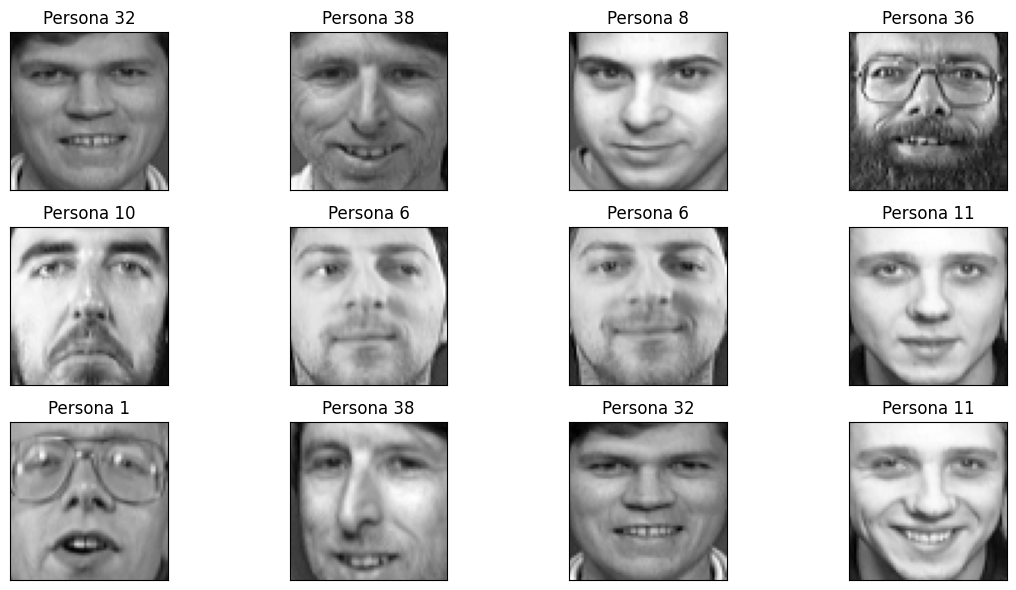

In [29]:
plt.figure(figsize=(12, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Persona {y_train[i]}")
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


---
# 2. Construir la red neuronal

Usaremos una arquitectura fully-connected similar a la vista en clase:

```text
Imagen 64×64
     ↓
Flatten
     ↓
4096 valores
     ↓
Dense(64)
     ↓
ReLU
     ↓
Dense(40)
     ↓
Logits
```

La última capa debe tener una salida por cada clase.

> **Importante:** no añadas `Softmax` al final. Trabajaremos directamente con **logits**.


In [30]:
# TODO 1 — Completar la arquitectura.

model = keras.Sequential([

    keras.Input(shape=(64, 64)),

    # Centrar aproximadamente la escala de entrada para reducir neuronas ReLU muertas.
    layers.Rescaling(scale=2.0, offset=-1.0),
    layers.Flatten(),

    layers.Dense(
        64,
        activation="relu"
    ),

    layers.Dense(40)
])

model.summary()



Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 40)             │         2,600 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 264,808 (1.01 MB)

 Trainable params: 264,808 (1.01 MB)

 Non-trainable params: 0 (0.00 B)

### Estandarización de las entradas

Las imágenes tienen valores entre 0 y 1 (todos positivos). Para evitar que la capa ReLU quede «muerta» y la red se quede en el nivel del azar, se estandarizan con la **media y la desviación estándar del conjunto de entrenamiento** y se aplican de la misma forma a train, validation y test (si alguno de los tres no se transforma, sus métricas dejan de ser comparables). El diagnóstico adicional (más abajo) muestra el efecto.


In [31]:
   mean, std = X_train.mean(), X_train.std()
   X_train = (X_train - mean) / std
   X_val = (X_val - mean) / std
   X_test = (X_test - mean) / std

In [32]:
# Validación TODO 1

assert isinstance(model, keras.Model)

# Dense(64): 4096*64 + 64
# Dense(40): 64*40 + 40
expected_params = (4096 * 64 + 64) + (64 * 40 + 40)

assert model.count_params() == expected_params, (
    f"Se esperaban {expected_params:,} parámetros, "
    f"pero el modelo tiene {model.count_params():,}."
)

print("✓ Arquitectura correcta.")
print(f"Parámetros entrenables: {model.count_params():,}")


✓ Arquitectura correcta.
Parámetros entrenables: 264,808


### Pregunta 2

¿Por qué necesitamos `Flatten()` antes de la primera capa `Dense`?

**Respuesta:** Porque `Dense` opera sobre un vector por ejemplo ($W\mathbf{x}+\mathbf{b}$). `Flatten()` transforma cada imagen $64\times64$ en un vector de 4096 componentes, sin parámetros.

### Pregunta 3

¿Por qué la última capa tiene **40 neuronas**?

**Respuesta:** Porque hay **40 personas** (clases 0–39): una neurona/logit por identidad.

### Pregunta 4

¿Qué función cumple `ReLU` en la capa oculta?

**Respuesta:** Introduce no linealidad, $\max(0,x)$, para que la red no colapse en una sola transformación lineal. Este ejercicio muestra también su punto débil: si la pre-activación es negativa para todos los ejemplos, la salida y el gradiente valen 0 y la neurona deja de aprender (*dying ReLU*, ver diagnóstico).



---
# 3. Configurar el entrenamiento

Las etiquetas son números enteros entre:

```text
0 y 39
```

Por eso usaremos:

```python
SparseCategoricalCrossentropy
```

Además:

- el modelo produce **logits**,
- usaremos **Adam**,
- mediremos **accuracy**.

Completa `model.compile()`.


In [33]:
lr_rate = 0.001

# TODO 2 — Configurar loss, optimizer y métrica.

model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=lr_rate
    ),

    loss=keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),

    metrics=["accuracy"]
)

print("✓ Modelo configurado.")


✓ Modelo configurado.


### Pregunta 5

¿Por qué usamos:

```python
from_logits=True
```

en la función de pérdida?

**Respuesta:** Porque `Dense(40)` devuelve **logits**, no probabilidades. `from_logits=True` indica a la pérdida que aplique Softmax internamente, de forma numéricamente estable, antes de calcular la cross-entropy.



---
# 4. Entrenar el modelo

Usaremos:

```python
epochs = 30
batch_size = 32
```

El dataset es pequeño, por lo que el entrenamiento debería ser rápido.

Keras realizará internamente:

```text
Forward pass
      ↓
Calcular loss
      ↓
Backpropagation
      ↓
Actualizar parámetros con Adam
```

Completa la llamada a `fit()`.


In [34]:
epochs = 30
batch_size = 32

# TODO 3 — Entrenar el modelo.

history = model.fit(

    X_train,
    y_train,

    epochs=epochs,
    batch_size=batch_size,

    validation_data=(X_val, y_val),

    shuffle=True
)


Epoch 1/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.0478 - loss: 5.2062 - val_accuracy: 0.2083 - val_loss: 3.2897
Epoch 2/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1838 - loss: 2.9192 - val_accuracy: 0.2292 - val_loss: 3.0636
Epoch 3/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.3309 - loss: 2.4096 - val_accuracy: 0.3125 - val_loss: 2.7177
Epoch 4/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.4779 - loss: 1.9033 - val_accuracy: 0.3542 - val_loss: 2.2459
Epoch 5/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6507 - loss: 1.3574 - val_accuracy: 0.5417 - val_loss: 1.7227
Epoch 6/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.7610 - loss: 0.9380 - val_accuracy: 0.6042 - val_loss: 1.4917
Epoch 7/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8419 - loss: 0.6194 - val_accuracy: 0.6250 - val_loss: 1.0841
Epoch 8/30
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9449 - loss: 0.3601 - val_accuracy: 0.7292 - val_loss: 0.8048


### Pregunta 6

¿Qué representa una **epoch**?

**Respuesta:** Una pasada completa por las 272 imágenes de entrenamiento (320 menos las 48 reservadas para validación).

### Pregunta 7

¿Qué significa `batch_size=32`?

**Respuesta:** Que cada actualización de pesos usa 32 imágenes; por eso cada epoch tiene $\lceil 272/32\rceil = 9$ actualizaciones (8 lotes de 32 y uno de 16), que es lo que muestra Keras como `9/9`.

---
## 4.1 Visualizar el entrenamiento

Esta parte está resuelta.

El dataset tiene muy pocos ejemplos comparado con el número de parámetros de la red.

Observa cuidadosamente la diferencia entre entrenamiento y validación.


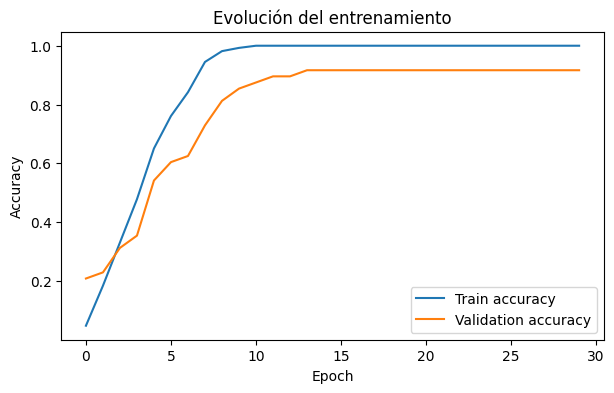

In [35]:
plt.figure(figsize=(7, 4))

plt.plot(
    history.history["accuracy"],
    label="Train accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Evolución del entrenamiento")
plt.legend()

plt.show()


### Pregunta 8

Observa las curvas de accuracy y loss de entrenamiento y validación. ¿Aprende el modelo? ¿Hay overfitting?

**Respuesta:**

**Sí aprende.** El accuracy de entrenamiento sube de 4.8 % (época 1) a 99.3 % (época 10) y llega a 100 % desde la época 15; el de validación sube de 20.8 % a 85.4 % (época 10) y a **91.7 %** (época 15 en adelante). La pérdida de validación baja de 3.29 a 0.29.

**Hay overfitting moderado.** El accuracy de entrenamiento es 100 % y el de validación 91.7 %: una brecha de ≈ 8 puntos. Además, desde la época 15 la validación se estanca en 91.7 % mientras el entrenamiento sigue mejorando (la pérdida de entrenamiento llega a 0.007 frente a 0.29 en validación): el modelo ya memoriza las 272 imágenes de entrenamiento. No es un overfitting «dañino», porque `val_loss` no sube (sigue bajando de 0.40 a 0.29), pero entrenar más épocas ya no mejora la validación. Con solo 48 imágenes de validación, cada imagen vale ≈ 2.1 puntos, así que estas cifras son ruidosas.

---
# 5. Evaluar el modelo

Ahora evaluaremos el modelo sobre imágenes que no fueron utilizadas para actualizar sus parámetros.

Completa `evaluate()`.


In [36]:
# TODO 4 — Evaluar.

test_loss, test_accuracy = model.evaluate(

    X_test,
    y_test,

    batch_size=batch_size,
    verbose=0
)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")
print(f"Accuracy (%)  : {test_accuracy * 100:.2f}%")


Test loss     : 0.5641
Test accuracy : 0.8750
Accuracy (%)  : 87.50%


## Diagnóstico adicional: efecto del preprocesamiento

Las imágenes de Olivetti tienen todos los píxeles entre 0 y 1 (no negativos). Con una red `Dense` + ReLU, esto puede hacer que muchas neuronas de la capa oculta queden «muertas» (devuelven 0 para todas las imágenes) y dejen de recibir gradiente. En una ejecución anterior, con las entradas sin centrar, el modelo se quedó en el nivel del azar (≈ 2.5 % de accuracy, pérdida ≈ ln 40 = 3.689), es decir, no aprendió nada.

**Resultados de esta ejecución:**

| Modelo | Neuronas muertas (de 64) | Accuracy de test |
|---|---|---|
| Principal (entradas estandarizadas + capa `Rescaling`) | 17 (≈ 27 %) | **87.5 %** (70 de 80) |
| Entradas centradas por píxel | 0 | **93.75 %** (75 de 80) |

**Interpretación:** centrar las entradas elimina las neuronas muertas y la variante centrada acierta 5 imágenes más en test. Pero es una sola ejecución con 80 imágenes de test, así que no puedo afirmar que la diferencia sea real: el resultado también depende de la inicialización. Lo que sí queda claro es que el preprocesamiento de las entradas decide si la red aprende o no.

In [37]:
# 1) ¿Cuántas neuronas ocultas quedaron "muertas" (salida 0 para todas las imágenes de train)?
def hidden_activations(m, X):
    # Reproduce el preprocesamiento hasta la primera capa Dense para poder
    # comparar tanto el modelo con Rescaling como el modelo con entradas centradas.
    activations = np.asarray(X)
    first_dense = None
    for layer in m.layers:
        if isinstance(layer, layers.Dense):
            first_dense = layer
            break
        activations = keras.ops.convert_to_numpy(layer(activations))
    if first_dense is None:
        raise ValueError("El modelo no contiene una capa Dense.")
    W, b = first_dense.get_weights()
    return np.maximum(0, activations.reshape(len(activations), -1) @ W + b)

h_train = hidden_activations(model, X_train)
dead = np.all(h_train == 0, axis=0)
print(f"Neuronas ReLU muertas en la capa Dense(64): {dead.sum()} de {dead.size}")


Neuronas ReLU muertas en la capa Dense(64): 17 de 64


Neuronas muertas con entradas centradas: 0 de 64
Train accuracy (última epoch): 1.0000 | train loss: 0.0019
Test accuracy                : 0.9375 | test loss : 0.2973


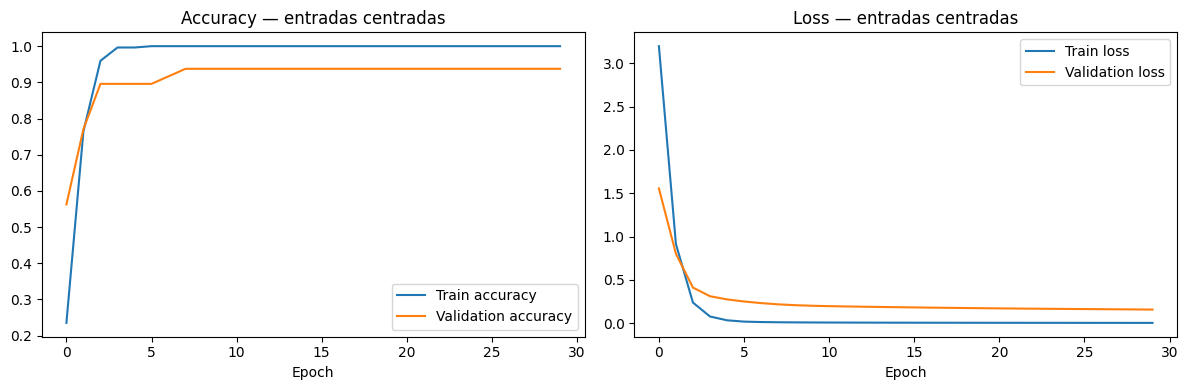

In [38]:
# 2) Comparación alternativa: entradas centradas por píxel (misma arquitectura Dense, preprocesamiento distinto)
keras.utils.set_random_seed(SEED)

pixel_mean = X_train.mean(axis=0)          # media calculada SOLO con train
X_train_c = X_train - pixel_mean
X_val_c = X_val - pixel_mean
X_test_c = X_test - pixel_mean

model_centered = keras.Sequential([
    keras.Input(shape=(64, 64)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(40),
])
model_centered.compile(
    optimizer=keras.optimizers.Adam(learning_rate=lr_rate),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)
history_c = model_centered.fit(
    X_train_c, y_train,
    epochs=epochs, batch_size=batch_size,
    validation_data=(X_val_c, y_val),
    shuffle=True, verbose=0,
)

h_c = hidden_activations(model_centered, X_train_c)
print("Neuronas muertas con entradas centradas:", int(np.all(h_c == 0, axis=0).sum()), "de 64")

loss_c, acc_c = model_centered.evaluate(X_test_c, y_test, verbose=0)
print(f"Train accuracy (última epoch): {history_c.history['accuracy'][-1]:.4f} | train loss: {history_c.history['loss'][-1]:.4f}")
print(f"Test accuracy                : {acc_c:.4f} | test loss : {loss_c:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_c.history["accuracy"], label="Train accuracy")
axes[0].plot(history_c.history["val_accuracy"], label="Validation accuracy")
axes[0].set_title("Accuracy — entradas centradas"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history_c.history["loss"], label="Train loss")
axes[1].plot(history_c.history["val_loss"], label="Validation loss")
axes[1].set_title("Loss — entradas centradas"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

### Pregunta 9

Tenemos **40 clases**, pero solamente **272 imágenes de entrenamiento** (después de reservar 48 para validación y 80 para test).

¿Crees que la cantidad de datos es grande o pequeña para una red con cientos de miles de parámetros?

**Respuesta:** **Pequeña.** 272 imágenes (≈ 6.8 por persona) para ajustar 264 808 parámetros: unos **974 parámetros por imagen** de entrenamiento. Con tantos grados de libertad la red puede memorizar cada foto en vez de aprender rasgos generales del rostro, y una variación de iluminación o expresión no vista puede confundirla. Es lo que se observa en las curvas: 100 % de accuracy en entrenamiento frente a 91.7 % en validación y 87.5 % en test.

---
# 6. Logits y Softmax

La salida de nuestro modelo tiene forma:

```text
(batch_size, 40)
```

Cada uno de los 40 valores corresponde al **logit** asociado a una persona.

Los logits no son probabilidades.

Para convertirlos en probabilidades usamos:

```python
keras.ops.softmax(...)
```


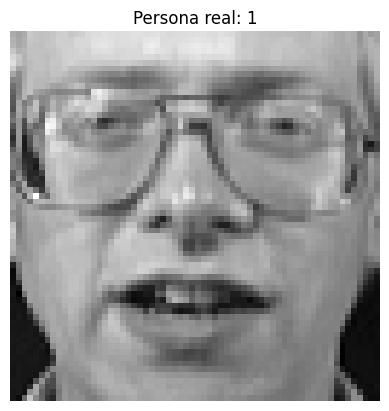

Shape de logits: (1, 40)

Primeros 10 logits:
[ -7.4387956   17.514084    -0.8653427   -0.9593293   -0.35368037
 -12.099639     9.496649     2.4781253   -2.306616    -4.2323184 ]


In [39]:
index = 0

image = X_test[index]
true_class = y_test[index]

plt.imshow(image, cmap="gray")
plt.title(f"Persona real: {true_class}")
plt.axis("off")
plt.show()

# Añadimos dimensión de batch:
# (64,64) -> (1,64,64)
image_batch = np.expand_dims(image, axis=0)

# Forward pass.
logits = model(
    image_batch,
    training=False
)

print("Shape de logits:", logits.shape)
print("\nPrimeros 10 logits:")
print(
    keras.ops.convert_to_numpy(logits)[0, :10]
)


In [40]:
# TODO 5 — Convertir logits a probabilidades.

probabilities = keras.ops.softmax(logits)

# TODO 6 — Obtener la clase con mayor probabilidad.

prediction = keras.ops.argmax(
    probabilities,
    axis=1
)

prediction = int(
    keras.ops.convert_to_numpy(prediction)[0]
)

print()
print("Persona real     :", true_class)
print("Persona predicha :", prediction)



Persona real     : 1
Persona predicha : 1


In [41]:
# Revisamos las cinco clases con mayor probabilidad.

probabilities_np = keras.ops.convert_to_numpy(
    probabilities
)[0]

top5 = np.argsort(
    probabilities_np
)[-5:][::-1]

print("Top 5 predicciones:\n")

for class_id in top5:
    print(
        f"Persona {class_id:2d}: "
        f"{probabilities_np[class_id]:.4f}"
    )

print(
    "\nSuma de probabilidades:",
    probabilities_np.sum()
)


Top 5 predicciones:

Persona  1: 0.9986
Persona 19: 0.0004
Persona 26: 0.0004
Persona  6: 0.0003
Persona 33: 0.0002

Suma de probabilidades: 0.9999999


### Pregunta 10

¿Por qué la suma de las 40 probabilidades obtenidas con `Softmax` debe ser aproximadamente `1`?

**Respuesta:** Softmax transforma los logits \(z_k\) en \(p_k=e^{z_k}/\sum_j e^{z_j}\). Cada probabilidad es no negativa y la suma de las 40 probabilidades es 1 (salvo pequeños errores de redondeo). La clase predicha es la que tenga la probabilidad más alta.

---
# 7. Visualizar varias predicciones

Esta parte está resuelta.

Observa especialmente los casos en los que el modelo se equivoca.


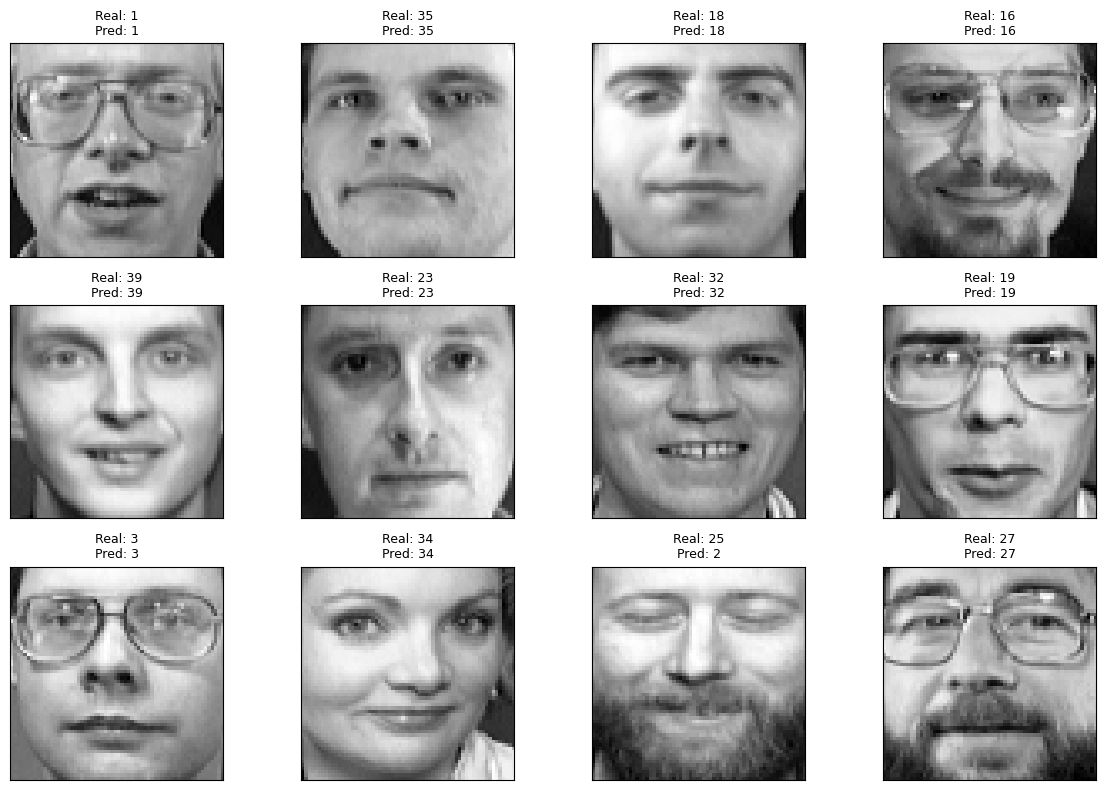

In [42]:
n = 12

logits_batch = model(
    X_test[:n],
    training=False
)

predictions = keras.ops.argmax(
    logits_batch,
    axis=1
)

predictions = keras.ops.convert_to_numpy(
    predictions
)

plt.figure(figsize=(12, 8))

for i in range(n):

    plt.subplot(3, 4, i + 1)

    plt.imshow(
        X_test[i],
        cmap="gray"
    )

    real = y_test[i]
    pred = predictions[i]

    plt.title(
        f"Real: {real}\nPred: {pred}",
        fontsize=9
    )

    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()


---
# 8. Reflexión final

Responde brevemente.

### 1. ¿Cuál fue el accuracy final del modelo?

**Respuesta:**

El accuracy final en **test fue 87.50 %** (70 de 80 imágenes; test loss 0.5641). En validación fue 91.67 % y en entrenamiento 100 %. Con 40 clases el azar sería 2.5 %, así que el modelo es muy superior al azar. La diferencia entre validación y test (≈ 4 puntos) es compatible con el ruido de evaluar con solo 48 y 80 imágenes.

### 2. ¿Observaste overfitting? ¿Qué evidencia utilizaste?

**Respuesta:**

Sí, moderado. La evidencia fue la brecha entre las curvas: el accuracy de entrenamiento llega a 100 % desde la época 15, mientras el de validación se estanca en ≈ 91.7 % y el de test es 87.5 %; además la pérdida de entrenamiento (0.007) es mucho menor que la de validación (0.29). La `val_loss` no sube, así que el modelo no empeora con más épocas, pero tampoco mejora.

### 3. ¿Qué ocurre cuando tenemos muchos parámetros pero pocos ejemplos de entrenamiento?

**Respuesta:**

El modelo tiene capacidad de sobra para **memorizar** los ejemplos de entrenamiento (incluido el ruido): el accuracy de entrenamiento llega a 100 % pero la generalización a imágenes nuevas es peor (alta varianza, overfitting). Aquí se vio con 264 808 parámetros y 272 imágenes (≈ 974 parámetros por imagen): 100 % en entrenamiento frente a 87.5 % en test. Para mitigarlo: más datos, data augmentation, regularización (Dropout, weight decay), un modelo más pequeño, early stopping o transfer learning.

### 4. Después de `Flatten()`, una cara de 64×64 se convierte en un vector de 4096 números.

¿Qué información sobre la estructura de la imagen deja de representar explícitamente esta transformación?

**Respuesta:**

La **estructura espacial**: qué píxeles son vecinos, y por tanto bordes, formas y partes de la cara (ojos, nariz, boca) y su posición relativa. Para la red cada píxel es una entrada independiente; no sabe que dos píxeles contiguos están relacionados. Además, si la cara se desplaza un poco o cambia la iluminación, el vector cambia mucho.

### 5. ¿Crees que una arquitectura diseñada específicamente para imágenes podría aprovechar mejor la información espacial?

**Respuesta:**

Sí. Una **CNN** usa filtros locales con pesos compartidos que detectan bordes y texturas en cualquier posición, y capas posteriores los combinan en partes de la cara; así aprovecha la vecindad de los píxeles, necesita muchos menos parámetros (menos riesgo de overfitting con pocos datos) y tolera pequeños desplazamientos.

---
# Resumen

En este ejercicio aplicaste nuevamente la receta básica de entrenamiento de una red neuronal:

```text
Dataset
   ↓
Train / Test split
   ↓
Sequential
   ↓
Flatten
   ↓
Dense + ReLU
   ↓
Dense(40)
   ↓
Cross-Entropy
   ↓
Adam
   ↓
fit()
   ↓
evaluate()
```

Los componentes de Keras son los mismos que usamos en clase.

Lo que cambió fue:

- el dataset,
- el tamaño de las imágenes,
- el número de clases,
- y la dificultad del problema.
